# Mini-Challenge DEL: Hyperparameter Tuning und Model Evaluation

In [1]:
# Standard Library
import os
import sys
import itertools
from pathlib import Path

# Third-Party Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.optim as optim
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from sklearn.model_selection import StratifiedKFold, cross_validate
from skorch import NeuralNetClassifier
from torch.utils.data import DataLoader


In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

## Erste Etappe: Daten Kennenlernen, Aufbau Modellierung & Basismodell
In dieser Phase legst du das Fundament für dein Deep Learning Projekt. Ziel ist es, die Daten zu verstehen, eine stabile Trainings-Pipeline aufzubauen und die Performance eines einfachen Basismodells als Referenzwert zu ermitteln.

### 1. Vorbereitung der Daten

* a) Explorative Analyse: Führe eine kurze Analyse der Features durch. Untersuche dabei insbesondere:
* Den Vergleich der Klassen pro Feature.
   * Die Balanciertheit der Klassen (Class Balance).
* b) Preprocessing: Implementiere geeignete Vorverarbeitungsschritte (z. B. Normalisierung oder Standardisierung der Daten).


In [3]:
# Laden des svhn
def load_svhn_data(batch_size=64):
    transform = transforms.Compose([
        transforms.ToTensor(),        
    ])

    train_dataset = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
    test_dataset = datasets.SVHN(root='../data', split='test', download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

train_loader, test_loader = load_svhn_data()


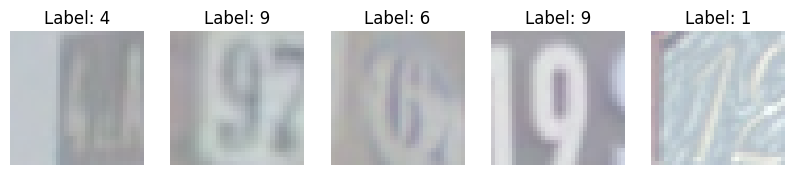

In [4]:
# EDA: Visualize some samples from the dataset
data_iter = iter(train_loader)
num_samples_to_show = 5

images, labels = next(data_iter)

plt.figure(figsize=(10, 2))
for i in range(num_samples_to_show):
    plt.subplot(1, num_samples_to_show, i + 1)
    plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)) * 0.5 + 0.5)
    plt.title(f'Label: {labels[i].item()}')
    plt.axis('off')
plt.show()


In [ ]:
# EDA: Klassen-Balanciertheit + Featurevergleich (RGB-Intensitäten je Klasse)

def prepare_labels(dataset):
    labels = np.array(dataset.labels)
    labels = np.where(labels == 10, 0, labels)
    return labels

def class_dist(labels, split_name="Train"):
    # Klassenverteilung
    class_counts = pd.Series(labels).value_counts().sort_index()
    class_pct = (class_counts / class_counts.sum() * 100).round(2)

    dist_df = pd.DataFrame({
        "Klasse": class_counts.index,
        "Anzahl": class_counts.values,
        "Anteil_%": class_pct.values
    })

    return dist_df, class_counts



def feature_comp(ds, labels, split_name="Train"):
    images = ds.data.astype(np.float32) / 255.0  # (N, C, H, W)

    # Featurevergleich: mittlere RGB-Intensitäten je Bild und Klasse
    mean_r = images[:, 0].mean(axis=(1, 2))
    mean_g = images[:, 1].mean(axis=(1, 2))
    mean_b = images[:, 2].mean(axis=(1, 2))
    mean_intensity = images.mean(axis=(1, 2, 3))

    feat_df = pd.DataFrame({
        "Klasse": labels,
        "Mean_R": mean_r,
        "Mean_G": mean_g,
        "Mean_B": mean_b,
        "Mean_Intensity": mean_intensity
    })

    class_feat = feat_df.groupby("Klasse")[["Mean_R", "Mean_G", "Mean_B", "Mean_Intensity"]].mean()
    print(f"\n=== {split_name}: Durchschnittliche Feature-Werte je Klasse ===")
    print(class_feat.round(4))

    # Visualisierungen
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.barplot(data=dist_df, x="Klasse", y="Anzahl", ax=axes[0], palette="viridis", hue="Anteil_%", dodge=False)
    axes[0].set_title(f"{split_name}: Klassenverteilung")
    axes[0].set_xlabel("Klasse")
    axes[0].set_ylabel("Anzahl")

    class_feat_plot = class_feat.reset_index().melt(
        id_vars="Klasse",
        value_vars=["Mean_R", "Mean_G", "Mean_B"],
        var_name="Feature",
        value_name="Mittelwert"
    )
    sns.barplot(data=class_feat_plot, x="Klasse", y="Mittelwert", hue="Feature", ax=axes[1], palette="Set2",)
    axes[1].set_title(f"{split_name}: RGB-Featurevergleich je Klasse")
    axes[1].set_xlabel("Klasse")
    axes[1].set_ylabel("Mittlere Intensität")
    axes[1].legend(title="Feature")

    plt.tight_layout()
    plt.show()


# EDA für Train und Test
train_labels = prepare_labels(train_loader.dataset)
test_labels = prepare_labels(test_loader.dataset)

for split_name, current_labels in [("Train", train_labels), ("Test", test_labels)]:
    dist_df, class_counts = class_dist(current_labels, split_name=split_name) 
    
    print(f"\n=== {split_name}: Klassenverteilung ===")
    print(dist_df.to_string(index=False))
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Imbalance-Ratio (max/min): {imbalance_ratio:.2f}")

feature_comp(train_loader.dataset, train_labels, split_name="Train")
feature_comp(test_loader.dataset, test_labels, split_name="Test")


In [ ]:
# Preprocessing der Daten
# calculate mean and std for normalization for each channel
def get_stats(loader):
    sum_, squared_sum, batches = 0, 0, 0
    
    for images, _ in loader:
        # images: [batch_size, 3, 32, 32]
        sum_ += torch.mean(images, dim=[0, 2, 3])
        squared_sum += torch.mean(images**2, dim=[0, 2, 3])
        batches += 1
        
    mean = sum_ / batches
    std = (squared_sum / batches - mean**2)**0.5
    return mean, std

# Berechnung
mean, std = get_stats(train_loader)
print(f"Mean: {mean}")
print(f"Std: {std}")


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_set = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
test_set = datasets.SVHN(root='../data', split='test', download=True, transform=transform)
    
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

# 2. Visualisieren
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Normalisiertes Bild Anzeigen:
plt.imshow(images[0].permute(1, 2, 0)) # Permute für (H, W, C)
plt.title(f"Label: {labels[0]}")
plt.show()

### 2. Evaluation

* Lege die Metriken fest, mit denen die Performance der Modelle gemessen werden soll (z. B. Accuracy, F1-Score, Loss).



### Metriken

Da der vorliegende Datensatz eine starke Klassenimbalance aufweist, ist die Accuracy als alleinige Metrik nicht aussagekräftig. Um die Modellleistung über alle Kategorien hinweg objektiv zu bewerten, fokussiere ich mich stattdessen auf den F1-Score sowie Precision und Recall.
Da es sich um ein Multiclass-Problem handelt, wird der CrossEntropyLoss als Verlustfunktion verwendet. Um sicherzustellen, dass auch minderbesetzte Klassen angemessen berücksichtigt werden, kommen bei der Evaluation die Macro-Averages (Macro F1, Macro Precision und Macro Recall) zum Einsatz. 


### 3. Implementierung der Basisfunktionalität

a) Training & Evaluation: Erstelle Funktionen oder Klassen für den standardisierten Trainings- und Evaluationsprozess.

b) MLOps Integration: Binde eine Plattform wie Weights & Biases (W&B) ein, um Experimente zu loggen.

c) Basismodell: Implementiere das vereinbarte einfache Basismodell.

d) Overfitting Test: Trainiere das Modell mit einem einzelnen Sample oder einem einzigen Batch. Wenn das Modell verlustfrei auf diesem Batch lernt, ist die Basisfunktionalität korrekt implementiert.


#### Design

1. **Konfiguration über `RunConfig`**
    - Zentrale Parameter (z. B. `learning_rate`, `batch_size`, `epochs`, `device`) werden in `baseline_config` gebündelt.

2. **Baseline-Training über `run_baseline(...)`**

3. **Experiment-Tracking mit Weights & Biases**
    - Aktiviert über `use_wandb=True` in der Config.
    - Projektname: `DEL`, Run-Name: `baseline-example`.

4. **Auswertung über `WandbRuns`**
    - lädt Runs aus W&B:
    ```python
    wandb_runs = WandbRuns(project="DEL")
    overview_df = wandb_runs.runs_overview(top_k=10)
    ```
    - Zusätzlich vergleichst du Metriken (z. B. `val/loss`) direkt zwischen Runs.


#### Struktur

```text
src/
├── training.py
│   ├── RunConfig            # Konfigurationsdataclass für Training
│   └── run_baseline(...)    # Führt Baseline-Training + Evaluation aus
├── wandb_tools.py
│   └── WandbRuns            # Laden, Filtern, Vergleichen von W&B-Runs
├── model.py            # Modellarchitekturen
└── metrics.py           # F1, Precision, Recall (Macro)
```

In [ ]:
# Overfitting-Test: Kann das Basismodell einen einzelnen Batch auswendig lernen?
from torch.utils.data import DataLoader, TensorDataset
from src.training import FitConfig, run_baseline, RunConfig

# single batch aus dem train_loader extrahieren
batch_images, batch_labels = next(iter(train_loader))
overfit_dataset = TensorDataset(batch_images.clone(), batch_labels.clone())
overfit_loader = DataLoader(overfit_dataset, batch_size=len(overfit_dataset), shuffle=False)

overfit_config = RunConfig(
    learning_rate=1e-2,
    batch_size=len(overfit_dataset),
    epochs=1000,
    use_wandb=False,
    wandb_project="DEL",
    run_name="overfit-single-batch",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["overfit-check"],
)

overfit_result = run_baseline(
    config=overfit_config,
    fit_config=FitConfig(epochs=1000),
    train_loader=overfit_loader,
)


In [ ]:
history = overfit_result["history"]
print(f"Final train accuracy: {history['train_accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history['val_accuracy'][-1]:.4f}")
print(f"Final train loss: {history['train_loss'][-1]:.4f}")
print(f"Final val loss: {history['val_loss'][-1]:.4f}")

In [ ]:
overfit_result["history"].keys()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(pd.DataFrame(history["train_accuracy"]))
axes[0].plot(pd.DataFrame(history["val_accuracy"]))
axes[0].set_title("Accuracy")
axes[0].legend(["Train", "Validation"])

axes[1].plot(pd.DataFrame(history["train_loss"]))
axes[1].plot(pd.DataFrame(history["val_loss"]))
axes[1].set_title("Loss")
axes[1].legend(["Train", "Validation"])

axes[2].plot(pd.DataFrame(history["train_macro_f1"]))
axes[2].plot(pd.DataFrame(history["val_macro_f1"]))
axes[2].set_title("F1 Score")
axes[2].legend(["Train", "Validation"])

plt.tight_layout()
plt.show(fig)

### 4. Training des Basismodells

In diesem Abschnitt wird die geforderte Basis-Konfiguration umgesetzt:
- SGD ohne Momentum
- keine Regularisierung (weight decay = 0)
- keine Batch-Normalization
- manuelles Tuning von Lernrate und Batchsize (kein Auto-Search)
- Schätzung des statistischen Fehlers mit Cross-Validation

#### 4a) Training mit SGD ohne Momentum/Regularisierung/BatchNorm (alle Trainingsdaten)

Es wird auf dem gesamten Trainingsset trainiert. Zur Lernkurven-Überwachung dient das offizielle Testset als Evaluationsset pro Epoche.

In [6]:
from src.training import run_baseline, RunConfig, FitConfig
from src.wandb_tools import WandbRuns

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
wandb_runs = WandbRuns(project="DEL", entity="lukas-breiter-fachhochschule-nordwestschweiz-fhnw")


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


In [ ]:
baseline_config = RunConfig(
    learning_rate=1e-2,
    batch_size=64,
    epochs=30,
    use_wandb=True,
    val_fraction=0.1,
    wandb_project="DEL",
    run_name="Baseline-Example",
    tags=["baseline"],
    device=DEVICE,
    random_seed=SEED,
    num_workers=4,
    pin_memory=torch.cuda.is_available(),
)
 
baseline_result = run_baseline(
    config=baseline_config,
    fit_config=FitConfig(epochs=baseline_config.epochs),
    train_loader=train_loader,
)

In [ ]:
baseline_example_hist = wandb_runs.history(
    run_path="lukas-breiter-fachhochschule-nordwestschweiz-fhnw/DEL/u4qgkxvz",
    keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"],
)

fig, axes = plt.subplots(4, 1, figsize=(15, 10))
axes[0].plot(baseline_example_hist["train/accuracy"], label="Train Accuracy")
axes[0].plot(baseline_example_hist["val/accuracy"], label="Val Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(baseline_example_hist["train/loss"], label="Train Loss")
axes[1].plot(baseline_example_hist["val/loss"], label="Val Loss")
axes[1].set_title("Loss")
axes[1].legend()

axes[2].plot(baseline_example_hist["train/macro_precision"], label="Train Macro Precision")
axes[2].plot(baseline_example_hist["val/macro_precision"], label="Val Macro Precision")
axes[2].set_title("Macro Precision")
axes[2].legend()

axes[3].plot(baseline_example_hist["train/macro_recall"], label="Train Macro Recall")
axes[3].plot(baseline_example_hist["val/macro_recall"], label="Val Macro Recall")
axes[3].set_title("Macro Recall")
axes[3].legend()

plt.tight_layout()
plt.show()


In [7]:
print("Finale Werte (4a):")
baseline_example_hist = baseline_example_hist.sort_values("_step")
print(f"val_loss: {baseline_example_hist['val/loss'].iloc[-1]:.4f}")
print(f"val_accuracy: {baseline_example_hist['val/accuracy'].iloc[-1]:.4f}")
print(f"val_macro_precision: {baseline_example_hist['val/macro_precision'].iloc[-1]:.4f}")
print(f"val_macro_recall: {baseline_example_hist['val/macro_recall'].iloc[-1]:.4f}")
print(f"val_macro_f1: {baseline_example_hist['val/macro_f1'].iloc[-1]:.4f}")

Finale Werte (4a):


NameError: name 'baseline_example_hist' is not defined

#### 4b) Manuelles Tuning von Lernrate und Batchsize (keine automatische Suche)

Für das Tuning wird ausschließlich die etablierte Funktion `run_baseline(...)` aus `src.training` verwendet.
Es wird ein kleiner manueller Grid getestet (kein Bayes, kein AutoML).

In [ ]:
learning_rates = [5e-2, 1e-2, 5e-3]
batch_sizes = [32, 64, 128]
tuning_epochs =  30

tuning_runs = []
histories = {}

for lr, bs in itertools.product(learning_rates, batch_sizes):
    run_name = f"Baseline_Tuning-lr{lr}-bs{bs}"
    train_loader_cfg,_ = load_svhn_data(batch_size=bs)

    result = run_baseline(
        config=RunConfig(
            learning_rate=lr,
            batch_size=bs,
            epochs=tuning_epochs,
            val_fraction=0.1,
            use_wandb=True,
            wandb_project="DEL",
            run_name=run_name,
            tags=["baseline"],
            device=DEVICE,
            random_seed=SEED,
            num_workers=4,
            pin_memory=torch.cuda.is_available(),
        ),
        fit_config=FitConfig(epochs=tuning_epochs),
        train_loader=train_loader_cfg,
    )

    h = result["history"]
    histories[(lr, bs)] = h
    tuning_runs.append(
        {
            "learning_rate": lr,
            "batch_size": bs,
            "val_loss": h["val_loss"][-1],
            "val_accuracy": h["val_accuracy"][-1],
            "val_macro_precision": h["val_macro_precision"][-1],
            "val_macro_recall": h["val_macro_recall"][-1],
            "val_macro_f1": h["val_macro_f1"][-1],
        }
    )

In [8]:
tuning_runs_list = pd.DataFrame(wandb_runs.runs_overview())

In [9]:
tuning_results = []
filtered_ids = set(tuning_runs_list["id"]) - {"u4qgkxvz"}

for run_id in filtered_ids:
    baseline_example_hist = wandb_runs.history(
        run_path=f"lukas-breiter-fachhochschule-nordwestschweiz-fhnw/DEL/{run_id}",
        keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", 
              "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"
              ],
    )

    hist_df = baseline_example_hist.copy()
    hist_df["run_id"] = run_id
    hist_df["learning_rate"] = tuning_runs_list.loc[tuning_runs_list["id"] == run_id, "name"].values[0].split("-")[1]
    hist_df["batch_size"] = tuning_runs_list.loc[tuning_runs_list["id"] == run_id, "name"].values[0].split("-")[2]
    tuning_results.append(hist_df)

tuning_result_df = pd.concat(tuning_results, ignore_index=True)
tuning_result_df.head()

,_step,val/macro_recall,val/macro_precision,val/macro_f1,val/loss,val/accuracy,train/accuracy,train/loss,train/macro_recall,train/macro_precision,train/macro_f1,run_id,learning_rate,batch_size
0,1,0.100000,0.019263,0.032303,2.238330,0.192628,0.185995,2.243150,0.100000,0.029596,0.036555,qocr1xkv,lr0.05,bs128
1,2,0.100000,0.019263,0.032303,2.237452,0.192628,0.188831,2.235065,0.100007,0.031385,0.031832,qocr1xkv,lr0.05,bs128
2,3,0.151387,0.385751,0.089249,3.033537,0.215427,0.267943,2.058378,0.177897,0.367126,0.155432,qocr1xkv,lr0.05,bs128
3,4,0.741985,0.810393,0.749081,0.746888,0.767509,0.735318,0.857742,0.702837,0.725688,0.711530,qocr1xkv,lr0.05,bs128
4,5,0.322816,0.715715,0.326083,3.225133,0.337065,0.848192,0.509934,0.832940,0.842571,0.837396,qocr1xkv,lr0.05,bs128


In [10]:
# Build one-row-per-run summary from tuning_result_df (last logged epoch per run)
tuning_df = (
    tuning_result_df
    .sort_values(["run_id", "_step"])
    .groupby("run_id", as_index=False)
    .tail(1)
    .loc[:, [
        "run_id",
        "learning_rate",
        "batch_size",
        "val/loss",
        "val/accuracy",
        "val/macro_precision",
        "val/macro_recall",
        "val/macro_f1",
    ]]
    .rename(columns={
        "val/loss": "val_loss",
        "val/accuracy": "val_accuracy",
        "val/macro_precision": "val_macro_precision",
        "val/macro_recall": "val_macro_recall",
        "val/macro_f1": "val_macro_f1",
    })
    .copy()
)

# Parse lr/bs strings like "lr0.01", "bs64"
tuning_df["learning_rate"] = tuning_df["learning_rate"].str.replace("lr", "", regex=False).astype(float)
tuning_df["batch_size"] = tuning_df["batch_size"].str.replace("bs", "", regex=False).astype(int)

tuning_df = tuning_df.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(tuning_df)

best_cfg = tuning_df.iloc[0]
best_lr = float(best_cfg["learning_rate"])
best_bs = int(best_cfg["batch_size"])
print(f"Beste Konfiguration nach val_macro_f1: lr={best_lr}, batch_size={best_bs}")

,run_id,learning_rate,batch_size,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1
0,qocr1xkv,0.050,128,0.539676,0.913038,0.912042,0.905004,0.908276
1,12qxs106,0.050,64,0.618152,0.908805,0.907606,0.899803,0.903208
2,59n1o4fr,0.010,64,0.342371,0.904437,0.905184,0.894668,0.899321
3,ohyxy98v,0.010,32,0.493527,0.904437,0.903237,0.894581,0.898364
4,kxviaumn,0.050,32,0.715772,0.904573,0.909506,0.890453,0.898325
5,l12peyho,0.005,32,0.402685,0.902253,0.899395,0.893138,0.895857
6,y7zwl74r,0.005,64,0.791768,0.766007,0.833870,0.727103,0.755012
7,luiklyhy,0.010,128,1.074455,0.703208,0.831665,0.628802,0.652162
8,590x18sv,0.005,128,2.016046,0.277543,0.508349,0.198899,0.165651


Beste Konfiguration nach val_macro_f1: lr=0.05, batch_size=128


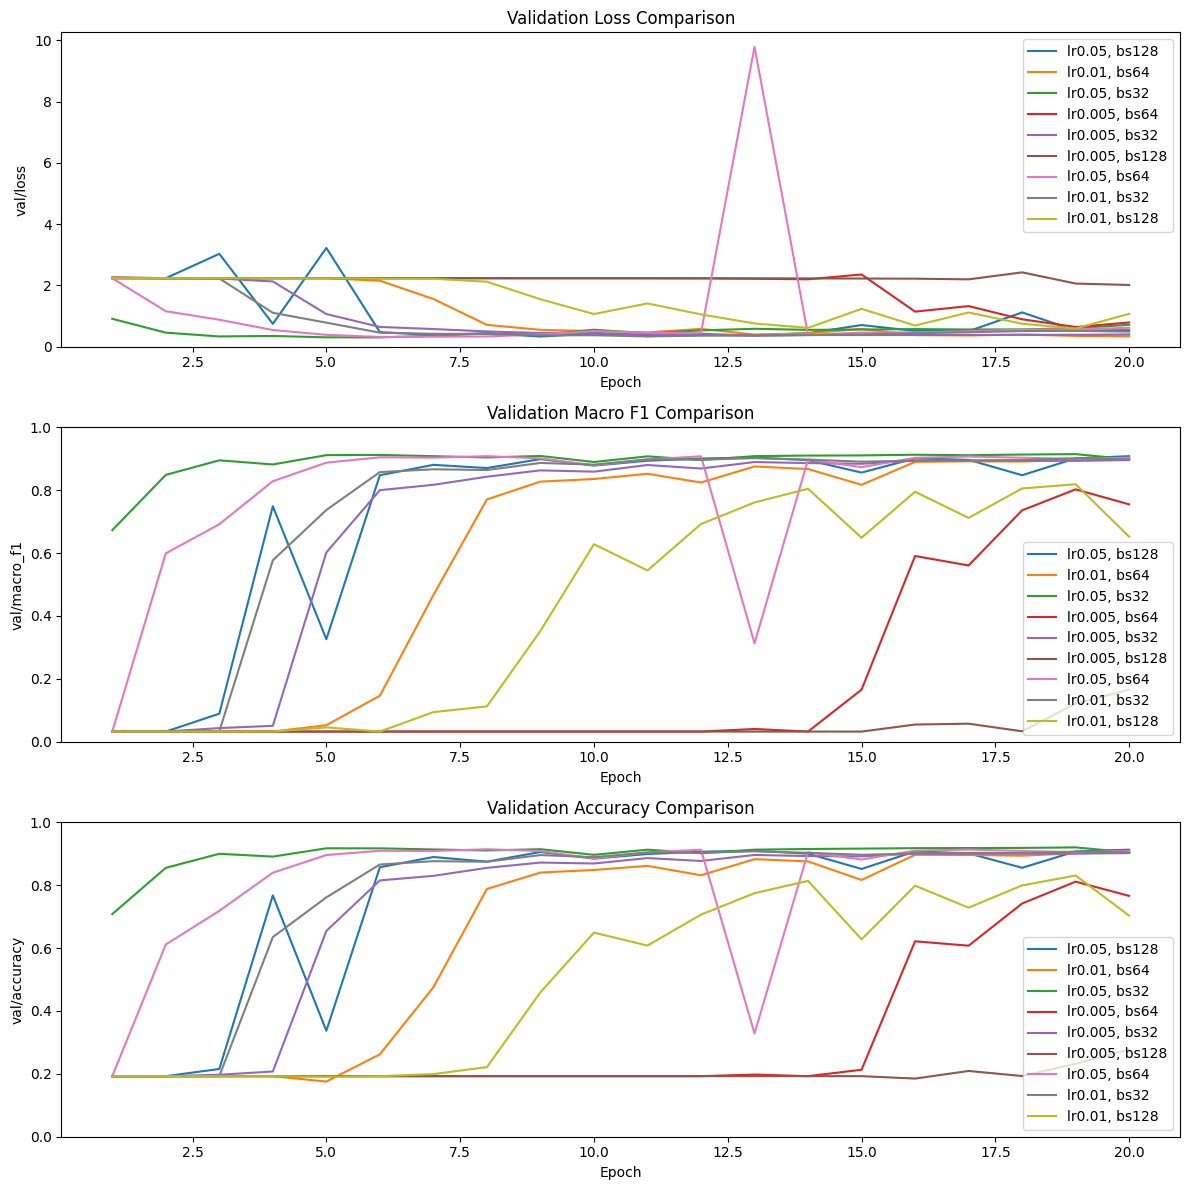

In [12]:
def plot_comparison(ax, metric_key):
    for run_id	in tuning_result_df["run_id"].unique():
            
        values = tuning_result_df.loc[tuning_result_df["run_id"] == run_id, metric_key]
        epochs = tuning_result_df.loc[tuning_result_df["run_id"] == run_id, "_step"]
        
        # Plot on the specific axis passed to the function
        ax.plot(epochs, values, label=f"{tuning_result_df.loc[tuning_result_df['run_id'] == run_id, 'learning_rate'].iloc[0]}, {tuning_result_df.loc[tuning_result_df['run_id'] == run_id, 'batch_size'].iloc[0]}")

    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric_key)
    ax.legend()

# 2. Create the layout first
fig, axes = plt.subplots(3,1, figsize=(12, 12))

# 3. Pass the specific subplot (axes[0] or axes[1]) to the function
plot_comparison(axes[0], "val/loss")
plot_comparison(axes[1], "val/macro_f1")
plot_comparison(axes[2], "val/accuracy")
axes[0].set_title("Validation Loss Comparison")
axes[1].set_title("Validation Macro F1 Comparison")
axes[2].set_title("Validation Accuracy Comparison")
axes[0].set_ylim(0, None)  # Loss sollte positiv sein
axes[1].set_ylim(0, 1)     # F1-Score liegt zwischen 0 und 1
axes[2].set_ylim(0, 1)     # Accuracy liegt zwischen 0 und 1



plt.tight_layout()
plt.show()

Theorie:
- Zu grosse Lernraten können zu Oszillation oder Divergenz führen (Blaue line am anfang)
- Zu kleine Lernraten konvergieren stabiler, benötigen aber viel mehr Epochen (alle linienen mit tiefer lernrate). Sie könnten in lokalen Minima stecken bleiben.
- Theoretisch: Kleinere Batches erzeugen noisigere Gradienten und können besser generalisieren,  sind rechenintensiver (über doppelt so lange).

Bei 20 Epochen sind die besten Gesamtkonfigurationen eine Lernrate von 0,05 und eine Batchgröße von 128. Damit wurden die höchste Validierungsgenauigkeit (0,913) sowie der stärkste Makro-F1-Wert (0,908) erzielt. Dies deutet darauf hin, dass das Modell nicht nur insgesamt, sondern auch über alle Klassen hinweg relativ ausgewogen gute Ergebnisse liefert.

Ein klares Muster ist, dass größere Batch-Größen nur in Kombination mit einer hohen Lernrate gut funktionieren. So schnitt die Batchgröße 128 bei einer Lernrate von 0,05 am besten ab, bei 0,01 jedoch deutlich schlechter und insbesondere bei 0,005, wo die Leistung stark abfiel. Dies deutet darauf hin, dass die niedrigeren Lernraten bei nur 20 Epochen wahrscheinlich zu gering waren, um das Modell ordnungsgemäß konvergieren zu lassen, insbesondere bei großen Batches.

Bei Batchgrößen von 32 und 64 sind die Ergebnisse stabiler. Die meisten Durchläufe erreichten eine Genauigkeit von etwa 0,90 bzw. 0,89–0,91 bei Makro-Präzision/Recall/F1. Dies deutet darauf hin, dass das Modell in diesem Bereich im Allgemeinen robust ist, obwohl keine dieser Einstellungen die Kombination 0,05/128 übertraf.

Insgesamt deuten die Ergebnisse darauf hin, dass 20 Epochen für Einstellungen mit hoher Lernrate ausreichten, um gut zu konvergieren, bei niedrigeren Lernraten und größeren Batch-Größen jedoch nicht. Würde das Training über 20 Epochen hinaus verlängert, könnten sich die schwächeren Läufe mit niedriger Lernrate verbessern. Doch basierend auf den aktuellen Ergebnissen ist 0,05 bei einer Batch-Größe von 128 die beste Wahl.


#### 4c) Schätzung des statistischen Fehlers mit Cross-Validation

Die Fold-Splits werden mit `kfold_indices(...)` aus `src.cross_validation` erzeugt.
Trainiert wird pro Fold mit `Trainer` aus `src.training` bei identischem Basismodell und SGD-Setup.

In [ ]:
from src.model import BaselineCNN

X = train_set.data.astype(np.float32)

if X.ndim == 4 and X.shape[1] == 3:
    pass
elif X.ndim == 4 and X.shape[-1] == 3:
    X = X.transpose(0, 3, 1, 2)
else:
    raise ValueError(f"Unexpected SVHN data shape: {X.shape}")

X = X / 255.0
X = (X - mean.numpy()[None, :, None, None]) / std.numpy()[None, :, None, None]
y = train_labels.astype(np.int64)

learning_rate = best_lr if "best_lr" in globals() else 1e-2
batch_size = best_bs if "best_bs" in globals() else 64

net = NeuralNetClassifier(
    BaselineCNN,
    max_epochs=20,
    module__num_classes=10,
    lr=learning_rate,
    batch_size=batch_size,
    optimizer=optim.SGD,
    optimizer__momentum=0.0,
    optimizer__weight_decay=0.0,
    criterion=torch.nn.CrossEntropyLoss,
    device=DEVICE,
    train_split=None,
    verbose=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "f1_macro", "precision_macro", "recall_macro"]

results = cross_validate(
    net, X, y, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1, 
    return_train_score=True,

)

cv_summary = pd.DataFrame({
    "metric": ["accuracy", "f1_macro", "precision_macro", "recall_macro"],
    "mean": [results[f"test_{m}"].mean() for m in scoring],
    "std": [results[f"test_{m}"].std() for m in scoring],
    "se": [results[f"test_{m}"].std() / np.sqrt(cv.get_n_splits()) for m in scoring],
})

display(cv_summary)


In [ ]:
#Vizualize 

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=cv_summary, x="metric", y="mean", palette="Set2", hue="metric", errorbar=None)

ax.errorbar(
	x=np.arange(len(cv_summary)),
	y=cv_summary["mean"],
	yerr=cv_summary["se"],
	fmt="none",
	ecolor="black",
	capsize=4,
)

plt.title("Cross-Validation Performance")
plt.ylim(0, 1)
plt.show()

## Etappe 2: Hyperparameter Tuning
Im Folgenden sollst Du nun den Trainingsverlauf und die Modellperformance unter Änderung verschiedener Hyperparameter untersuchen. Hierzu sollst Du mind. 10 Hypothesen formulieren, Experimente durchführen, um die Hypothesen zu testen, und die Ergebnisse einordnen und reflektieren.

**Vorgehen pro Hypothese** 

Für jede Hypothese gehst du wie folgt vor:

1. Hypothese: Formuliere deine Erwartung dazu, was sich in der Modellperformance und/oder dem Trainingsverlauf ändert, wenn ein Hyperparameter verändert wird. Begründe diese Hypothese mit Hilfe deines theoretischen Wissens und gib eine entsprechende Referenz an.
2. Experiment: Definiere ein Experiment, mit welchem die Hypothese getestet werden kann und führe es durch.
3. Analyse/Reflexion: Analysiere die Ergebnisse daraufhin, ob sich die Hypothese bestätigt hat, und reflektiere darüber.

**Themengruppen für die Hypothesen**

Die Hypothesen sollen aus folgenden Bereichen gebildet werden:

* Modellkomplexität:
    * Anzahl Conv-Layer und/oder Anzahl linearer Layer (Modelltiefe)
    * Anzahl Filter pro Conv-Layer oder Anzahl Units in linearen Layern (Breite)
   
   Hinweis: Gegebenenfalls muss die Lernrate angepasst werden.
* Settings bei Conv-Layern:
    * Kernel Size
    * Pooling
* Regularisierung:
    * Dropout
    * Data Augmentation
* Verwendung von BatchNorm
* Initialisierung der Gewichte
* Verwendung des Adam Optimizers
* Transfer Learning

### Hypothese 1: Grössere Modelltiefe verbessert die Generalisierung

$H_0: F(M_{\text{deep}}) \leq F(B)$

$H_1: F(M_{\text{deep}}) > F(B)$

Ein moderat tieferes CNN sollte hierarchischere Merkmale lernen und dadurch den Macro-F1 verbessern; erhofft wird insbesondere eine robustere Trennung ähnlich aussehender Ziffern.

### Hypothese 2: Grössere Modellbreite erhöht die Repräsentationskraft

$H_0: F(M_{\text{wide}}) \leq F(B)$

$H_1: F(M_{\text{wide}}) > F(B)$

Mehr Filter bzw. mehr Units sollten die Merkmalsrepräsentation stärken; erwartet wird ein höherer Macro-F1, solange Overfitting durch Regularisierung kontrolliert bleibt. 


### Hypothese 3: Kleinere Kernel ((3\times3) statt (5\times5)) generalisieren besser

$H_0: F(M_{k=3}) \leq F(B)$

$H_1: F(M_{k=3}) > F(B)$

Kleinere Kernel reduzieren die Parameterzahl und erlauben feinere, gestapelte Merkmalsextraktion; erhofft wird daher ein leicht besserer Macro-F1 bei stabilerem Training.


### Hypothese 4: Weniger aggressives Pooling ist für SVHN vorteilhaft

$H_0: F(M_{\text{pool-late}}) \leq F(B)$

$H_1: F(M_{\text{pool-late}}) > F(B)$

Da SVHN kleine natürliche Bildausschnitte mit teils feinen Zifferndetails enthält, könnte späteres oder reduziertes Pooling mehr relevante Information erhalten; erhofft wird ein besserer Macro-F1.



### Hypothese 5: Moderates Dropout verbessert die Testleistung

$H_0: F(M_{\text{drop}=0.3}) \leq F(B)$

$H_1: F(M_{\text{drop}=0.3}) > F(B)$

Moderates Dropout sollte Co-Adaptation reduzieren und Overfitting im Klassifikationskopf dämpfen; erwartet wird vor allem eine bessere Generalisierung auf dem Testset.



### Hypothese 6: Data Augmentation erhöht die Robustheit des Modells

$H_0: F(M_{\text{aug}}) \leq F(B)$

$H_1: F(M_{\text{aug}}) > F(B)$

Leichte Augmentationen wie kleine Translationen, Rotationen oder Helligkeitsänderungen sollten die Varianz der Trainingsdaten erhöhen; erhofft wird ein höherer Macro-F1 und ein geringerer Generalisierungsfehler.



### Hypothese 7: Batch Normalization stabilisiert und verbessert das Training

$H_0: F(M_{\text{BN}}) \leq F(B)$

$H_1: F(M_{\text{BN}}) > F(B)$

BatchNorm sollte die Optimierung erleichtern und die Konvergenz beschleunigen; erwartet wird ein glatterer Trainingsverlauf und mindestens ein leicht besserer Macro-F1.

### Hypothese 8: He-Initialisierung ist für ReLU geeigneter als Xavier

$H_0: F(M_{\text{He}}) \leq F(M_{\text{Xav}})$

$H_1: F(M_{\text{He}}) > F(M_{\text{Xav}})$

Da das Modell ReLU-Aktivierungen verwendet, sollte He-Initialisierung die Gradienten besser skalieren als Xavier; erhofft wird ein stabilerer Start und bessere Endleistung.



### Hypothese 9: Adam konvergiert schneller als SGD und erreicht mindestens gleiche Leistung

$H_0: F(M_{\text{Adam}}) \leq F(M_{\text{SGD}})$

$H_1: F(M_{\text{Adam}}) > F(M_{\text{SGD}})$

Adam passt die Lernrate parameterweise an und ist oft bei verrauschten Gradienten effizient; erwartet wird ein schnellerer Lernfortschritt und ein mindestens leicht höherer Macro-F1. 

### Hypothese 10: Transfer Learning schlägt Training from scratch

$H_0: F(M_{\text{TL}}) \leq F(B)$

$H_1: F(M_{\text{TL}}) > F(B)$

Ein vortrainiertes Modell sollte bereits nützliche visuelle Grundmerkmale enthalten; erhofft wird deshalb eine schnellere Konvergenz und eine bessere Testleistung als beim reinen Training von Grund auf.